# 6장. Matplotlib/Seaborn 최소한

| 항목 | 내용 |
|---|---|
| 예상 시간 | 2시간 |
| 선수 장 | 4장, 5장 |
| 이 장의 결과물 | 카테고리 분포 막대그래프, 혼동 행렬 형태의 히트맵 PNG |
| 과제 연결 | "혼동 행렬을 시각화한다" |

**학습 목표**
- `fig, ax` 구조로 그래프를 그리고 파일로 저장할 수 있다.
- 카테고리 분포를 막대그래프로 그리고 막대 위에 숫자를 표시할 수 있다.
- 행렬을 숫자가 적힌 히트맵으로 그리고, 행 기준 비율 히트맵도 만들 수 있다.
- 한글 글꼴을 설정해 한글과 마이너스 기호가 깨지지 않게 할 수 있다.

이 과제에서 그래프는 많이 필요하지 않습니다. **혼동 행렬 히트맵** 하나가 필수이고, 분포 막대그래프는 데이터를 설명할 때 유용합니다. 그 두 가지에 필요한 만큼만 배웁니다.

In [2]:
EN_CATEGORIES = ["comp.graphics", "comp.windows.x", "rec.sport.baseball", "rec.sport.hockey", "sci.space"]

import tempfile
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import fetch_20newsgroups

WORK = Path(tempfile.mkdtemp())   # 그림 파일은 임시 폴더에 저장한다

## 6.1 Figure와 Axes, 그리고 저장

Matplotlib 그림은 두 층으로 되어 있습니다.
- **Figure(`fig`)**: 그림 전체, 즉 도화지입니다. 크기와 저장을 담당합니다.
- **Axes(`ax`)**: 도화지 안의 그래프 한 칸입니다. 선, 막대, 축 이름, 제목을 담당합니다.

`fig, ax = plt.subplots()`로 둘을 함께 만들고, 그리기는 `ax.메서드()`로 합니다. `plt.plot()`처럼 `plt`에 바로 그리는 방식도 있지만, 그래프가 여러 개가 되면 어디에 그리는지 헷갈리므로 **`ax`에 그리는 방식**을 권합니다.

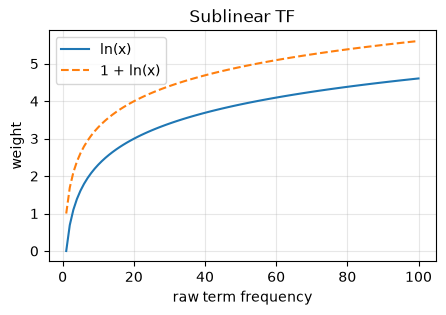

저장: sublinear_tf.png 30,869 bytes


In [3]:
x = np.arange(1, 101)

fig, ax = plt.subplots(figsize=(5, 3))          # 가로 5인치, 세로 3인치
ax.plot(x, np.log(x), label="ln(x)")
ax.plot(x, 1 + np.log(x), label="1 + ln(x)", linestyle="--")
ax.set_title("Sublinear TF")
ax.set_xlabel("raw term frequency")
ax.set_ylabel("weight")
ax.legend()
ax.grid(alpha=0.3)

path = WORK / "sublinear_tf.png"
fig.savefig(path, dpi=150, bbox_inches="tight")   # bbox_inches: 바깥 여백을 잘라 글자가 잘리지 않게
plt.show()
print("저장:", path.name, f"{path.stat().st_size:,} bytes")

- `fig.savefig`는 **`plt.show()`보다 먼저** 호출합니다. 일부 환경에서는 `show` 뒤에 그림이 비워집니다.
- `dpi`는 해상도입니다. README에 넣을 그림은 120~150이면 충분합니다.
- 여러 그림을 반복문으로 만들 때는 저장 후 `plt.close(fig)`로 닫아야 메모리가 쌓이지 않습니다.

여러 칸을 한 번에 만들려면 `plt.subplots(행 수, 열 수)`를 씁니다. 이때 `ax`는 배열이 됩니다.

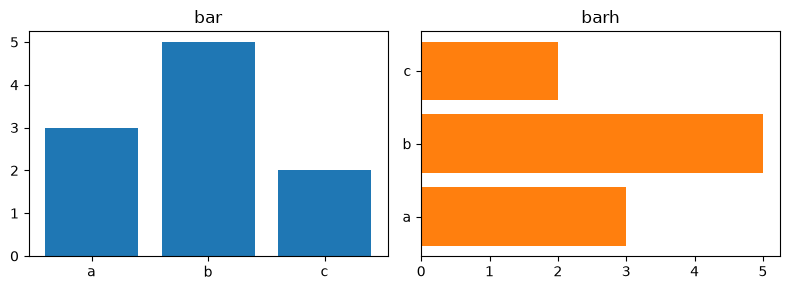

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].bar(["a", "b", "c"], [3, 5, 2])
axes[0].set_title("bar")
axes[1].barh(["a", "b", "c"], [3, 5, 2], color="tab:orange")
axes[1].set_title("barh")
fig.tight_layout()          # 칸끼리 글자가 겹치지 않게 간격 조정
plt.show()

## 6.2 막대그래프: 카테고리 분포

5장에서 본 20 Newsgroups 카테고리 분포를 그립니다. 카테고리 이름이 길면 **가로 막대(`barh`)**가 읽기 편합니다. `ax.bar_label`로 막대 끝에 숫자를 붙입니다.

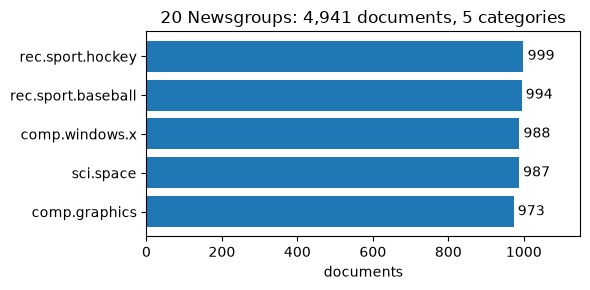

In [4]:
bunch = fetch_20newsgroups(subset="all", categories=EN_CATEGORIES,
                           remove=("headers", "footers", "quotes"), random_state=42)
labels = pd.Series([bunch.target_names[t] for t in bunch.target])
counts = labels.value_counts().sort_values()     # 작은 값이 아래로 가도록 정렬

fig, ax = plt.subplots(figsize=(6, 3))
bars = ax.barh(counts.index, counts.values, color="tab:blue")
ax.bar_label(bars, padding=3)
ax.set_title(f"20 Newsgroups: {len(labels):,} documents, {len(counts)} categories")
ax.set_xlabel("documents")
ax.set_xlim(0, counts.max() * 1.15)              # 숫자가 들어갈 오른쪽 여백
fig.tight_layout()
plt.show()

막대 길이가 비슷하므로 **클래스 불균형이 거의 없다**는 것을 한눈에 알 수 있습니다. 리포트에서 "카테고리가 고르게 분포한다"고 쓸 때 근거 그림으로 씁니다.

## 6.3 히트맵: 혼동 행렬 미리 보기

**혼동 행렬**(19장)은 "실제 정답 × 예측" 표입니다. 행이 실제, 열이 예측이고, $(i, j)$ 칸은 실제 $i$인 문서를 $j$로 예측한 개수입니다. 대각선은 맞힌 개수, 나머지는 틀린 개수입니다. 숫자 표는 패턴이 잘 안 보이므로 **색으로 칠한 히트맵**으로 그립니다.

여기서는 가짜 숫자로 그리는 법만 익힙니다.

In [5]:
class_names = ["space", "baseball", "hockey"]
cm = np.array([[50,  3,  2],
               [ 4, 45, 11],
               [ 1,  9, 49]])

### Matplotlib만으로 그리기
`imshow`로 색을 칠하고, 칸마다 `ax.text`로 숫자를 씁니다. 배경이 진한 칸은 글자를 흰색으로 바꿔 읽기 쉽게 합니다.

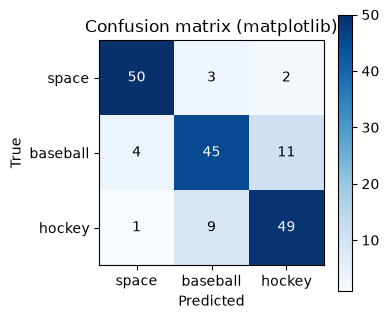

In [6]:
fig, ax = plt.subplots(figsize=(4, 3.5))
im = ax.imshow(cm, cmap="Blues")
fig.colorbar(im, ax=ax)

ax.set_xticks(range(len(class_names)), labels=class_names)
ax.set_yticks(range(len(class_names)), labels=class_names)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")

threshold = cm.max() / 2
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        color = "white" if cm[i, j] > threshold else "black"
        ax.text(j, i, cm[i, j], ha="center", va="center", color=color)
ax.set_title("Confusion matrix (matplotlib)")
fig.tight_layout()
plt.show()

### Seaborn으로 그리기
Seaborn의 `heatmap`은 숫자 표시와 글자색 처리를 자동으로 해 줍니다.

| 인자 | 의미 |
|---|---|
| `annot=True` | 칸에 숫자 쓰기 |
| `fmt="d"` / `fmt=".2f"` | 정수로 / 소수 둘째 자리까지 |
| `cmap="Blues"` | 색 지도 |
| `xticklabels`, `yticklabels` | 축 눈금 이름 |
| `vmin`, `vmax` | 색 범위 고정 (여러 그림을 같은 기준으로 비교할 때) |

혼동 행렬은 개수뿐 아니라 **행 기준 비율**(실제 클래스 중 몇 %를 무엇으로 예측했나)로도 많이 봅니다. 4장의 브로드캐스팅으로 각 행을 행 합계로 나눕니다.

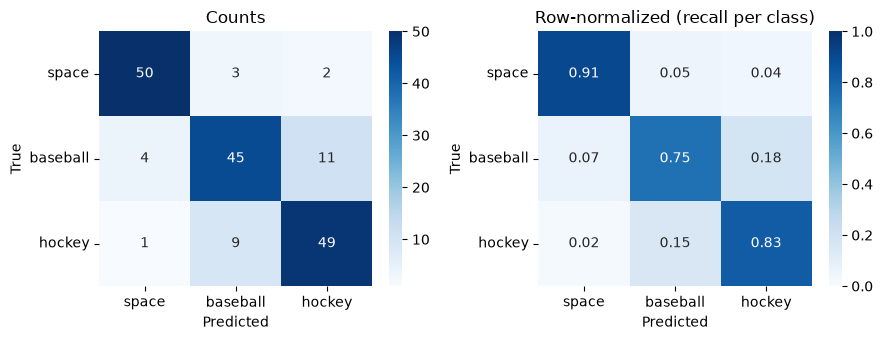

In [7]:
cm_ratio = cm / cm.sum(axis=1, keepdims=True)      # (3, 3) / (3, 1): 행마다 나누기

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=class_names, yticklabels=class_names)
axes[0].set_title("Counts")
sns.heatmap(cm_ratio, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[1],
            xticklabels=class_names, yticklabels=class_names)
axes[1].set_title("Row-normalized (recall per class)")
for ax in axes:
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.tick_params(axis="y", rotation=0)   # seaborn은 세로축 눈금을 눕혀 그린다
fig.tight_layout()
plt.show()

비율 그림을 보면 `baseball → hockey`(0.18)와 `hockey → baseball`(0.15) 칸이 눈에 띕니다. 두 스포츠는 `game`, `team`, `season`, `player` 같은 단어를 공유하므로 BoW 모델이 헷갈리기 쉽습니다. 이런 해석이 19–20장 분석의 출발점입니다.

> seaborn은 과제 허용 라이브러리지만 필수는 아닙니다. 쓰기로 했다면 `requirements.txt`에도 추가해야 합니다.

## 6.4 한글 글꼴 설정

Matplotlib 기본 글꼴(DejaVu Sans)에는 한글이 없어서, 한글 라벨은 **네모(□)로 깨지고** 경고가 쏟아집니다. 한국어 데이터의 카테고리(`정치`, `경제` …)를 그릴 때 문제가 됩니다.

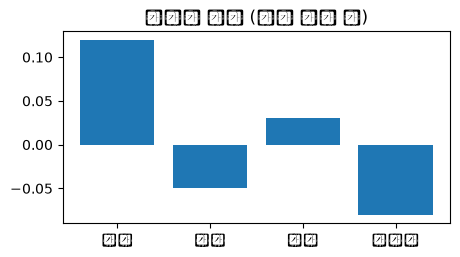

글꼴 경고 수: 38


In [8]:
ko_counts = pd.Series({"정치": 1000, "경제": 1000, "사회": 1000, "생활문화": 1000,
                       "세계": 1000, "IT과학": 1000, "스포츠": 1000})
change = pd.Series({"정치": 0.12, "경제": -0.05, "사회": 0.03, "스포츠": -0.08})   # 예시 숫자

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    fig, ax = plt.subplots(figsize=(5, 2.5))
    ax.bar(change.index, change.values)
    ax.set_title("주제별 변화 (글꼴 설정 전)")
    fig.canvas.draw()                       # 그려 봐야 글꼴 경고가 나온다
    plt.show()
print("글꼴 경고 수:", sum("Glyph" in str(w.message) for w in caught))

운영체제마다 기본으로 있는 한글 글꼴이 다르므로, 후보 중 **설치된 것을 찾아** 설정하는 함수를 만듭니다. 이 함수를 프로젝트의 그림 그리는 코드 맨 앞에서 한 번 호출하면 됩니다.

| 운영체제 | 글꼴 |
|---|---|
| macOS | AppleGothic, Apple SD Gothic Neo |
| Windows | Malgun Gothic (맑은 고딕) |
| Linux | NanumGothic (`sudo apt install fonts-nanum` 후 Matplotlib 캐시 삭제) |

글꼴을 한글용으로 바꾸면 그 글꼴에 유니코드 마이너스 기호(−)가 없어 **음수의 `-`가 깨지는** 문제가 따라옵니다. `axes.unicode_minus = False`로 일반 하이픈(-)을 쓰게 합니다.

In [9]:
from matplotlib import font_manager


def set_korean_font() -> str | None:
    """설치된 한글 글꼴을 찾아 Matplotlib 기본 글꼴로 설정한다. 찾은 글꼴 이름을 돌려준다."""
    candidates = ["AppleGothic", "Apple SD Gothic Neo", "Malgun Gothic", "NanumGothic"]
    installed = {f.name for f in font_manager.fontManager.ttflist}
    for name in candidates:
        if name in installed:
            plt.rcParams["font.family"] = name
            plt.rcParams["axes.unicode_minus"] = False
            return name
    return None


print("설정한 글꼴:", set_korean_font())

설정한 글꼴: AppleGothic


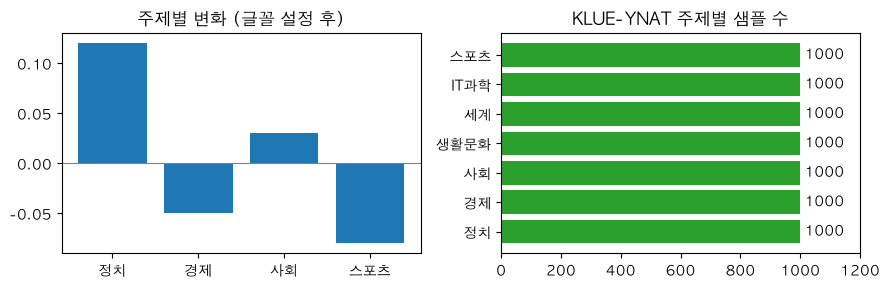

글꼴 경고 수: 0


In [10]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    fig, axes = plt.subplots(1, 2, figsize=(9, 3))
    axes[0].bar(change.index, change.values)
    axes[0].axhline(0, color="gray", lw=0.8)
    axes[0].set_title("주제별 변화 (글꼴 설정 후)")
    bars = axes[1].barh(ko_counts.index, ko_counts.values, color="tab:green")
    axes[1].bar_label(bars, padding=3)
    axes[1].set_xlim(0, 1200)
    axes[1].set_title("KLUE-YNAT 주제별 샘플 수")
    fig.tight_layout()
    fig.canvas.draw()
    plt.show()
print("글꼴 경고 수:", sum("Glyph" in str(w.message) for w in caught))

> **글꼴을 못 찾는다면?** 글꼴을 설치한 직후에는 Matplotlib이 예전 글꼴 목록(캐시)을 쓰고 있을 수 있습니다. `matplotlib.get_cachedir()` 폴더를 지우고 커널을 재시작하세요.
>
> **다른 방법:** 그래프에서만 레이블을 영어로 바꿔 쓰면(`정치 → Politics`) 글꼴 문제를 아예 피할 수 있습니다. 평가자 컴퓨터에 한글 글꼴이 없어도 그림이 깨지지 않으므로, 제출용 그림에는 이 방법도 좋습니다.

## ✍️ 실습: 혼동 행렬 히트맵 저장하기

아래 행렬로 다음 조건을 만족하는 그림을 만들어 `WORK / "cm_practice.png"`에 저장하세요.

1. 왼쪽: 개수 히트맵(정수 표시), 오른쪽: 행 기준 비율 히트맵(소수 둘째 자리, 색 범위 0~1)
2. 축 이름은 `예측`(가로), `실제`(세로), 눈금 이름은 `class_names_ko`
3. 그림 전체 제목: `"혼동 행렬 연습"` (`fig.suptitle`)
4. 저장 후 파일이 존재하는지 출력

In [11]:
class_names_ko = ["우주", "야구", "하키"]
cm_practice = np.array([[88,  7,  5],
                        [ 6, 80, 14],
                        [ 2, 12, 86]])

In [12]:
# 여기에 작성하세요

**정답**

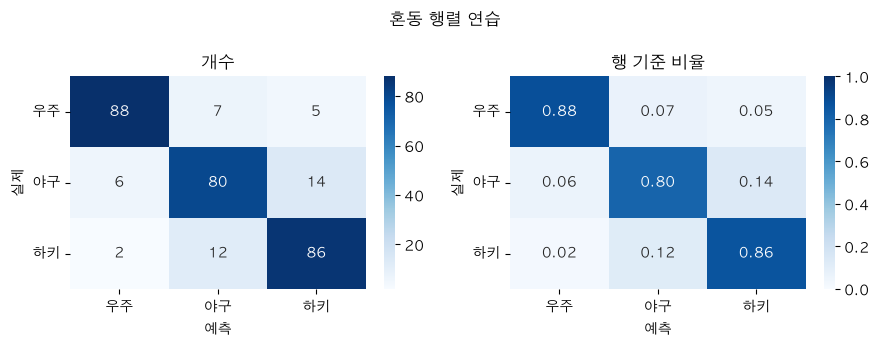

파일 존재: True (46,065 bytes)


In [13]:
set_korean_font()
ratio = cm_practice / cm_practice.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
sns.heatmap(cm_practice, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=class_names_ko, yticklabels=class_names_ko)
sns.heatmap(ratio, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[1],
            xticklabels=class_names_ko, yticklabels=class_names_ko)
axes[0].set_title("개수")
axes[1].set_title("행 기준 비율")
for ax in axes:
    ax.set_xlabel("예측")
    ax.set_ylabel("실제")
    ax.tick_params(axis="y", rotation=0)
fig.suptitle("혼동 행렬 연습")
fig.tight_layout()

out = WORK / "cm_practice.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print("파일 존재:", out.exists(), f"({out.stat().st_size:,} bytes)")

## 🧐 퀴즈

**Q1.** `fig`와 `ax`는 각각 무엇을 담당하나요?
<details><summary>▶ 정답 보기</summary>

`fig`는 그림 전체(도화지)로 크기 지정과 파일 저장을 담당하고, `ax`는 그 안의 그래프 한 칸으로 막대·선·축 이름·제목을 담당합니다.
</details>

**Q2.** 저장한 PNG가 빈 그림으로 나왔습니다. 가장 흔한 원인은?
<details><summary>▶ 정답 보기</summary>

`plt.show()`를 먼저 호출한 뒤 `savefig`를 했기 때문입니다. `show` 이후에는 그림이 비워질 수 있으므로 `savefig`를 먼저 호출합니다.
</details>

**Q3.** 혼동 행렬을 행 기준 비율로 바꾸는 NumPy 코드는? 비율로 보면 좋은 점은?
<details><summary>▶ 정답 보기</summary>

`cm / cm.sum(axis=1, keepdims=True)`. 클래스마다 문서 수가 달라도 "실제 클래스 중 몇 %를 맞혔고 무엇으로 헷갈렸는지"를 같은 기준으로 비교할 수 있습니다. 대각선 값이 클래스별 재현율(recall)입니다.
</details>

**Q4.** 한글 글꼴을 설정했더니 음수의 마이너스 기호가 깨집니다. 해결 방법은?
<details><summary>▶ 정답 보기</summary>

`plt.rcParams["axes.unicode_minus"] = False`로 설정해 유니코드 마이너스(−) 대신 일반 하이픈(-)을 쓰게 합니다.
</details>

## ✅ 체크포인트
- [ ] `fig, ax = plt.subplots()`로 그리고 `savefig`로 저장할 수 있다.
- [ ] 가로 막대그래프에 숫자 라벨을 붙일 수 있다.
- [ ] 개수 히트맵과 행 기준 비율 히트맵을 그릴 수 있다.
- [ ] 한글 글꼴과 마이너스 기호 문제를 해결할 수 있다.

## 🔗 과제 연결과 다음 장
- 히트맵 코드는 19장에서 실제 분류 결과의 `confusion_matrix.png`를 만드는 데 그대로 쓰입니다.
- 분포 막대그래프는 7장 데이터 소개와 리포트에 씁니다.
- Part 2(데이터 도구)가 끝났습니다. **7장. NLP 개요와 데이터셋**부터 본격적으로 과제 데이터를 다룹니다.